In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, special

SEED = 1231083982
rng = np.random.default_rng(SEED)

step_rngs = rng.spawn(8)
bonus_b_rng = rng.spawn(1)[0]

print("Project setup successful!")

Project setup successful!


In [2]:
# Step 1: From CDF to Density

N = 100000
rng1 = step_rngs[0]

# Generate 100,000 samples for each distribution
uniform_samples = rng1.uniform(0, 1, N)
exponential_samples = rng1.exponential(1, N)
gaussian_samples = rng1.normal(0, 1, N)
rayleigh_samples = rng1.rayleigh(1, N)

# Check the number of samples
print("Uniform samples:", len(uniform_samples))
print("Exponential samples:", len(exponential_samples))
print("Gaussian samples:", len(gaussian_samples))
print("Rayleigh samples:", len(rayleigh_samples))

Uniform samples: 100000
Exponential samples: 100000
Gaussian samples: 100000
Rayleigh samples: 100000


### Step 1: Theoretical CDFs and PDFs

**1. Uniform Distribution U(0,1)**

Support: $0 \leq x \leq 1$

PDF:

$$
f(x)=
\begin{cases}
1, & 0 \leq x \leq 1\\
0, & \text{otherwise}
\end{cases}
$$

CDF:

$$
F(x)=
\begin{cases}
0, & x<0\\
x, & 0\leq x\leq 1\\
1, & x>1
\end{cases}
$$

**2. Exponential Distribution (rate = 1)**

Support: $x \geq 0$

PDF:

$$
f(x)=e^{-x}, \quad x\geq 0
$$

CDF:

$$
F(x)=1-e^{-x}, \quad x\geq 0
$$

Both functions are 0 for $x<0$.

**3. Standard Gaussian Distribution N(0,1)**

Support: $-\infty < x < \infty$

PDF:

$$
f(x)=\frac{1}{\sqrt{2\pi}}e^{-x^2/2}
$$

CDF:

$$
F(x)=\frac{1}{\sqrt{2\pi}}
\int_{-\infty}^{x}e^{-t^2/2}\,dt
$$

**4. Rayleigh Distribution (scale = 1)**

Support: $x \geq 0$

PDF:

$$
f(x)=xe^{-x^2/2}, \quad x\geq 0
$$

CDF:

$$
F(x)=1-e^{-x^2/2}, \quad x\geq 0
$$

Both functions are 0 for $x<0$.

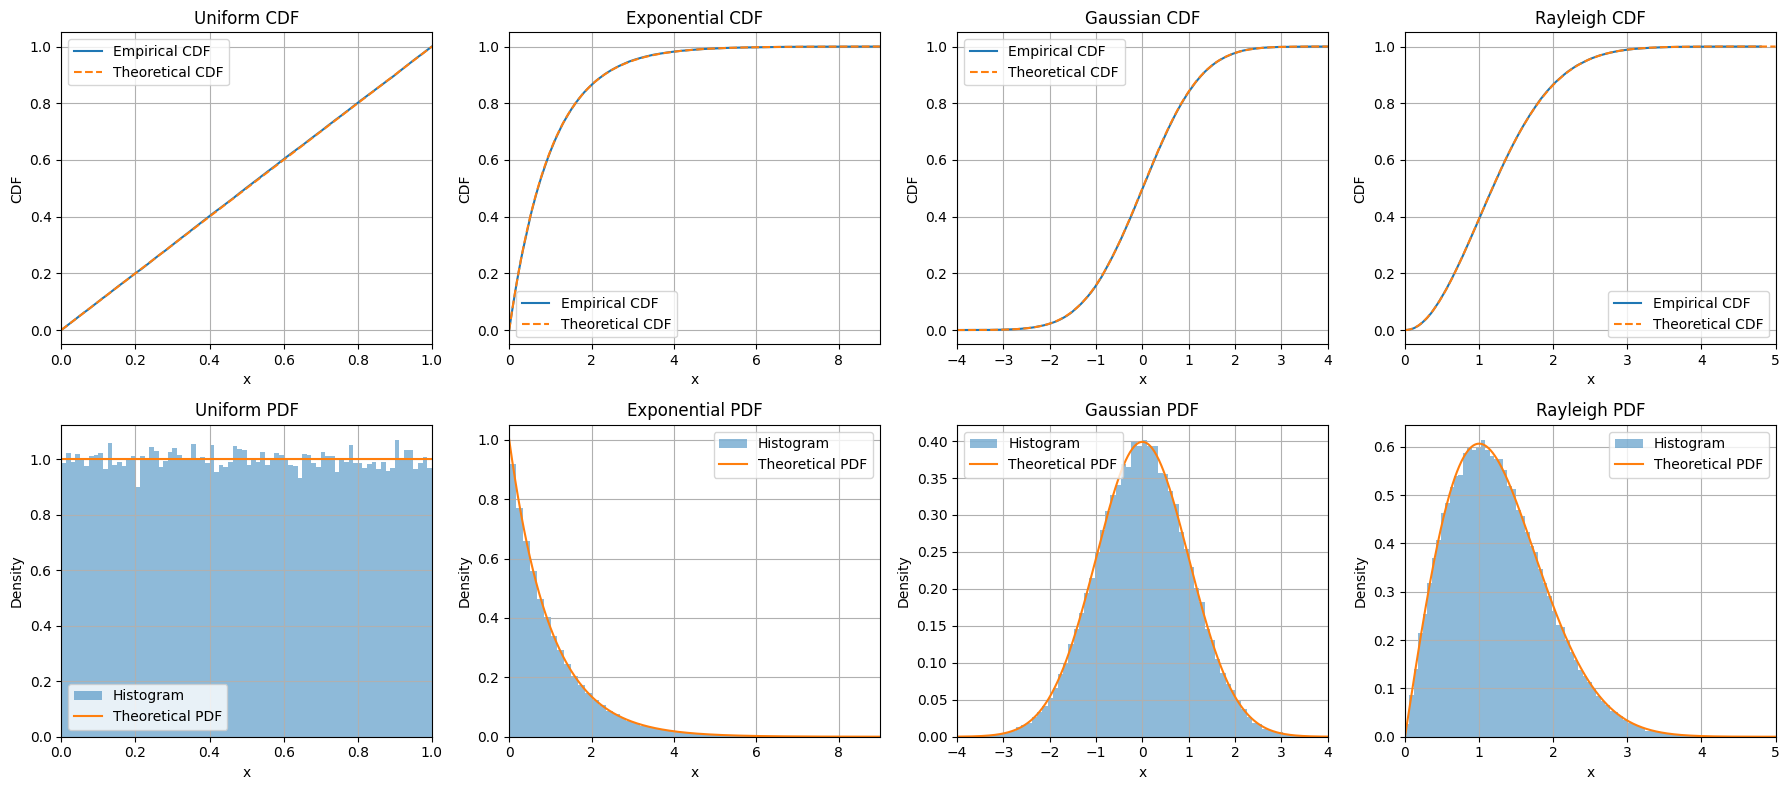

In [3]:
# Step 1: Figure 1 - CDFs and PDFs

distributions = [
    ("Uniform", uniform_samples, stats.uniform(), (0, 1)),
    ("Exponential", exponential_samples, stats.expon(), (0, 9)),
    ("Gaussian", gaussian_samples, stats.norm(), (-4, 4)),
    ("Rayleigh", rayleigh_samples, stats.rayleigh(), (0, 5))
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for i, (name, samples, dist, limits) in enumerate(distributions):

    x = np.linspace(limits[0], limits[1], 500)

    # Empirical CDF
    sorted_samples = np.sort(samples)
    empirical_cdf = np.arange(1, N + 1) / N

    axes[0, i].plot(sorted_samples, empirical_cdf,
                    label="Empirical CDF")
    axes[0, i].plot(x, dist.cdf(x), "--",
                    label="Theoretical CDF")

    axes[0, i].set_title(name + " CDF")
    axes[0, i].set_xlabel("x")
    axes[0, i].set_ylabel("CDF")
    axes[0, i].set_xlim(limits)
    axes[0, i].legend()
    axes[0, i].grid(True)

    # Histogram and theoretical PDF
    axes[1, i].hist(samples, bins=80, density=True,
                    alpha=0.5, label="Histogram")
    axes[1, i].plot(x, dist.pdf(x),
                    label="Theoretical PDF")

    axes[1, i].set_title(name + " PDF")
    axes[1, i].set_xlabel("x")
    axes[1, i].set_ylabel("Density")
    axes[1, i].set_xlim(limits)
    axes[1, i].legend()
    axes[1, i].grid(True)

plt.tight_layout()
plt.show()

### Figure 1 Interpretation

Figure 1 compares the empirical and theoretical CDFs
and PDFs for the four distributions using 100,000 samples
each. The empirical CDFs closely follow the theoretical
curves, and the normalized histograms show the expected
density shapes.

The uniform distribution has a constant density, the
exponential distribution decreases as x increases, the
Gaussian distribution is symmetric, and the Rayleigh
distribution increases to a peak before decreasing.

The KS statistics are 0.002775, 0.003457, 0.002861,
and 0.002199, respectively. All four values are below
the 95% critical value of 0.004301, so none of the
distributions is rejected by the KS test.

### Mean and Median Comparison

The exponential distribution is right-skewed, so its
long right tail pulls the mean above the median,
making the mean approximately 1.44 times the median.

The Gaussian distribution is symmetric around zero,
so its theoretical mean and median are both zero.

In [4]:
# Step 1: KS Statistics

from mp2lib import ks_statistic

critical_value = 1.36 / np.sqrt(N)

print("Step 1: KS Statistics")
print(f"95% Critical Value: {critical_value:.6f}")
print("-" * 50)
print(f"{'Distribution':<15} {'KS Statistic':<15} {'Result'}")

for name, samples, dist, limits in distributions:
    ks = ks_statistic(samples, dist.cdf)
    result = "Pass" if ks < critical_value else "Fail"
    print(f"{name:<15} {ks:<15.6f} {result}")

Step 1: KS Statistics
95% Critical Value: 0.004301
--------------------------------------------------
Distribution    KS Statistic    Result
Uniform         0.002775        Pass
Exponential     0.003457        Pass
Gaussian        0.002861        Pass
Rayleigh        0.002199        Pass


In [5]:
# Step 1: Mean, Median, and Variance

print("Exponential Distribution")
print(f"Sample Mean: {np.mean(exponential_samples):.4f}")
print(f"Theoretical Mean: {1.0:.4f}")
print(f"Sample Median: {np.median(exponential_samples):.4f}")
print(f"Theoretical Median: {np.log(2):.4f}")
print(f"Sample Variance: {np.var(exponential_samples, ddof=1):.4f}")
print(f"Theoretical Variance: {1.0:.4f}")

print("\nRayleigh Distribution")
print(f"Sample Mean: {np.mean(rayleigh_samples):.4f}")
print(f"Theoretical Mean: {np.sqrt(np.pi / 2):.4f}")
print(f"Sample Median: {np.median(rayleigh_samples):.4f}")
print(f"Theoretical Median: {np.sqrt(2 * np.log(2)):.4f}")
print(f"Sample Variance: {np.var(rayleigh_samples, ddof=1):.4f}")
print(f"Theoretical Variance: {(4 - np.pi) / 2:.4f}")

Exponential Distribution
Sample Mean: 1.0016
Theoretical Mean: 1.0000
Sample Median: 0.6978
Theoretical Median: 0.6931
Sample Variance: 0.9978
Theoretical Variance: 1.0000

Rayleigh Distribution
Sample Mean: 1.2533
Theoretical Mean: 1.2533
Sample Median: 1.1807
Theoretical Median: 1.1774
Sample Variance: 0.4285
Theoretical Variance: 0.4292


### Theoretical Mean, Median, and Variance

**Exponential Distribution (rate = 1)**

Mean: $\mu = \frac{1}{\lambda} = 1$

Median: $m = \frac{\ln 2}{\lambda} = 0.6931$

Variance: $\sigma^2 = \frac{1}{\lambda^2} = 1$

**Rayleigh Distribution (scale = 1)**

Mean: $\mu = \sigma\sqrt{\frac{\pi}{2}} = 1.2533$

Median: $m = \sigma\sqrt{2\ln 2} = 1.1774$

Variance: $\mathrm{Var}(X) = \frac{4-\pi}{2}\sigma^2 = 0.4292$

## Step 2: Build Your Own Generator by Inversion

### Inverse CDF Sampling

If $U$ is uniformly distributed on $[0,1]$ and $F$ is a continuous, strictly increasing CDF, we can generate a random variable $X$ with CDF $F$ using

$$
X=F^{-1}(U).
$$

Proof:

$$
P(X\leq x)=P(F^{-1}(U)\leq x)
$$

$$
=P(U\leq F(x))=F(x).
$$

Therefore, $F^{-1}(U)$ has the desired CDF.

### Exponential Inverse CDF

For an exponential distribution with rate $\lambda$,

$$
F(x)=1-e^{-\lambda x}.
$$

Setting $u=F(x)$,

$$
u=1-e^{-\lambda x}
$$

$$
1-u=e^{-\lambda x}
$$

$$
\ln(1-u)=-\lambda x.
$$

Solving for $x$ gives

$$
F^{-1}(u)=\frac{-\ln(1-u)}{\lambda}.
$$

### Rayleigh Inverse CDF

For a Rayleigh distribution with scale $\sigma$,

$$
F(x)=1-e^{-x^2/(2\sigma^2)}.
$$

Setting $u=F(x)$,

$$
1-u=e^{-x^2/(2\sigma^2)}
$$

$$
\ln(1-u)=-\frac{x^2}{2\sigma^2}
$$

$$
x^2=-2\sigma^2\ln(1-u).
$$

Therefore,

$$
F^{-1}(u)=\sigma\sqrt{-2\ln(1-u)}.
$$

In [6]:
# Step 2: Inverse CDF Sampling

from mp2lib import (
    inv_cdf_exponential,
    inv_cdf_rayleigh,
    sample_by_inversion,
    ks_statistic
)

N2 = 100000
rng2 = step_rngs[1]

# Generate samples using our inverse CDF functions
exp_inv = sample_by_inversion(
    inv_cdf_exponential, N2, rng2, lam=1
)

ray_inv = sample_by_inversion(
    inv_cdf_rayleigh, N2, rng2, sigma=1
)

# Generate samples using NumPy for comparison
exp_lib = rng2.exponential(1, N2)
ray_lib = rng2.rayleigh(1, N2)

# KS statistics against the theoretical CDF
ks_exp = ks_statistic(exp_inv, stats.expon.cdf)
ks_ray = ks_statistic(ray_inv, stats.rayleigh.cdf)

ks_exp_lib = ks_statistic(exp_lib, stats.expon.cdf)
ks_ray_lib = ks_statistic(ray_lib, stats.rayleigh.cdf)

critical2 = 1.36 / np.sqrt(N2)

print("Step 2: Inverse CDF Sampling")
print(f"95% Critical Value: {critical2:.6f}")

print("\nExponential Distribution")
print(f"Inversion KS: {ks_exp:.6f}")
print(f"Library KS: {ks_exp_lib:.6f}")
print("Inversion passes:", ks_exp < critical2)

print("\nRayleigh Distribution")
print(f"Inversion KS: {ks_ray:.6f}")
print(f"Library KS: {ks_ray_lib:.6f}")
print("Inversion passes:", ks_ray < critical2)

# Two-sample comparison against the library generators
print("\nTwo-Sample KS Comparison")
print(f"Exponential: {stats.ks_2samp(exp_inv, exp_lib).statistic:.6f}")
print(f"Rayleigh: {stats.ks_2samp(ray_inv, ray_lib).statistic:.6f}")

Step 2: Inverse CDF Sampling
95% Critical Value: 0.004301

Exponential Distribution
Inversion KS: 0.001600
Library KS: 0.003157
Inversion passes: True

Rayleigh Distribution
Inversion KS: 0.002912
Library KS: 0.004225
Inversion passes: True

Two-Sample KS Comparison
Exponential: 0.003090
Rayleigh: 0.004590


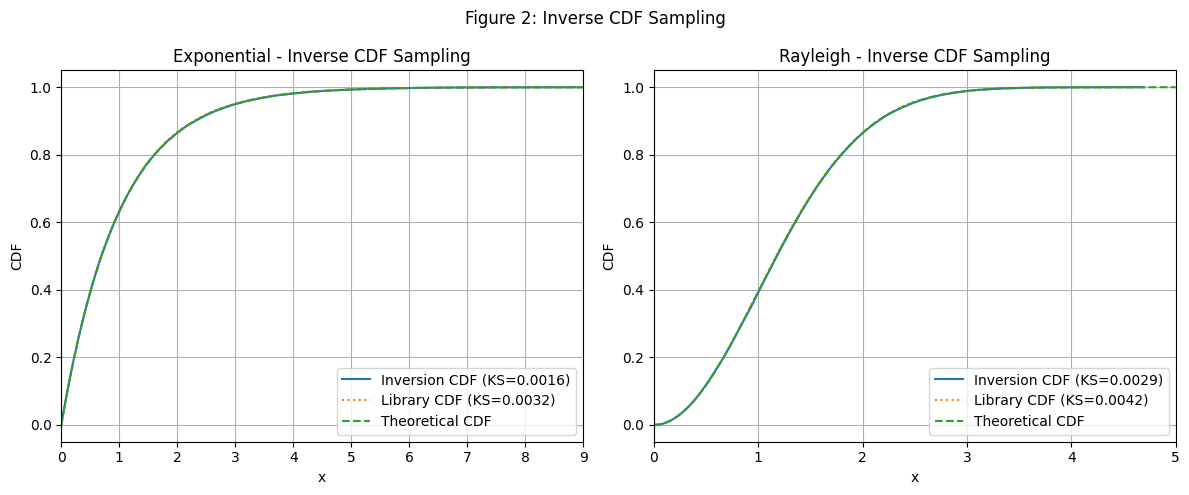

In [7]:
# Step 2: Figure 2

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

data2 = [
    ("Exponential", exp_inv, exp_lib,
     stats.expon, ks_exp, ks_exp_lib, (0, 9)),

    ("Rayleigh", ray_inv, ray_lib,
     stats.rayleigh, ks_ray, ks_ray_lib, (0, 5))
]

for ax, (name, inv_samples, lib_samples,
         dist, ks_inv, ks_lib, limits) in zip(axes, data2):

    x = np.linspace(limits[0], limits[1], 500)

    inv_sorted = np.sort(inv_samples)
    lib_sorted = np.sort(lib_samples)

    ecdf = np.arange(1, N2 + 1) / N2

    ax.plot(inv_sorted, ecdf,
            label=f"Inversion CDF (KS={ks_inv:.4f})")

    ax.plot(lib_sorted, ecdf, ":",
            label=f"Library CDF (KS={ks_lib:.4f})")

    ax.plot(x, dist.cdf(x), "--",
            label="Theoretical CDF")

    ax.set_title(name + " - Inverse CDF Sampling")
    ax.set_xlabel("x")
    ax.set_ylabel("CDF")
    ax.set_xlim(limits)
    ax.legend()
    ax.grid(True)

plt.suptitle("Figure 2: Inverse CDF Sampling")
plt.tight_layout()
plt.show()

### Figure 2 Interpretation

Figure 2 compares samples generated using inverse CDF
sampling with the theoretical CDFs and NumPy's library
generators.

Both inverse CDF generators closely follow their
theoretical distributions. The exponential inversion KS
statistic is approximately 0.0016, and the Rayleigh
inversion KS statistic is approximately 0.0029. Both are
below the 95% critical value of 0.0043.

The library-generated samples also agree with their
theoretical CDFs. These results support the correctness
of the inverse CDF sampling implementations.

### Edge Case Handling

The implementation uses `np.log1p(-u)` to calculate
$\ln(1-u)$ accurately, including when $u$ is close to zero.

When $u=0$, both inverse CDF functions return zero,
which is a valid value on their supports.

NumPy's `rng.random()` generates values in $[0,1)$,
so it does not produce $u=1$, which would cause
the inverse CDF to become infinite.

### Equivalent Exponential Inverse Forms

Both $-\ln(U)/\lambda$ and $-\ln(1-U)/\lambda$ generate
the same exponential distribution because $U$ and
$1-U$ are both uniformly distributed on $[0,1]$.

Our implementation uses $-\ln(1-U)/\lambda$.

## Step 3: A Function of a Random Variable

Let $X\sim N(0,1)$ and define $Y=X^2$.

### Derivation of the CDF

Since $Y=X^2$, the support of $Y$ is $y\geq 0$.

For $y>0$,

$$
F_Y(y)=P(Y\leq y)
$$

$$
=P(X^2\leq y)
$$

$$
=P(-\sqrt{y}\leq X\leq\sqrt{y}).
$$

Using the standard Gaussian CDF $\Phi$,

$$
F_Y(y)=\Phi(\sqrt{y})-\Phi(-\sqrt{y}).
$$

Because the standard Gaussian is symmetric,

$$
\Phi(-a)=1-\Phi(a).
$$

Therefore,

$$
F_Y(y)=2\Phi(\sqrt{y})-1,\qquad y>0.
$$

For $y\leq 0$, the CDF is zero.

### Derivation of the PDF

Differentiate the CDF:

$$
f_Y(y)=\frac{d}{dy}[2\Phi(\sqrt{y})-1].
$$

Using the chain rule,

$$
f_Y(y)=2\phi(\sqrt{y})\frac{1}{2\sqrt{y}},
$$

where

$$
\phi(x)=\frac{1}{\sqrt{2\pi}}e^{-x^2/2}.
$$

Thus,

$$
f_Y(y)=\frac{1}{\sqrt{2\pi y}}e^{-y/2},
\qquad y>0.
$$

The density is zero for $y<0$.

### Why the Density Diverges Near Zero

As $y$ approaches zero from the positive side,

$$
f_Y(y)\sim\frac{1}{\sqrt{2\pi}}y^{-1/2}.
$$

The density becomes unbounded because the squaring
transformation is flat near $x=0$. A small interval
around zero in the original Gaussian distribution is
compressed into an even smaller interval after squaring.

However, the total probability remains finite because
the singularity $y^{-1/2}$ is integrable near zero:

$$
\int_0^\epsilon y^{-1/2}\,dy=2\sqrt{\epsilon}.
$$

Therefore, an unbounded PDF can still integrate to one.

### Analytical Mean and Variance

Since $Y=X^2$ and $X$ is standard Gaussian,

$$
E[Y]=E[X^2]=1.
$$

Also,

$$
E[Y^2]=E[X^4]=3.
$$

Therefore,

$$
\operatorname{Var}(Y)=E[Y^2]-(E[Y])^2
$$

$$
=3-1^2=2.
$$

### Analytical Probabilities and Median

For any $a>0$,

$$
P(Y\leq a)=2\Phi(\sqrt{a})-1.
$$

Therefore,

$$
P(Y\leq 1)=2\Phi(1)-1\approx 0.6827,
$$

and

$$
P(Y\leq 0.1)=2\Phi(\sqrt{0.1})-1\approx 0.2482.
$$

For the median $m$, set $F_Y(m)=0.5$:

$$
2\Phi(\sqrt{m})-1=0.5
$$

$$
\Phi(\sqrt{m})=0.75
$$

$$
m=[\Phi^{-1}(0.75)]^2\approx 0.4549.
$$

In [8]:
# Step 3: Gaussian Transformation Y = X^2

from scipy.integrate import quad

N3 = 1000000
rng3 = step_rngs[2]

# Generate standard Gaussian samples
x3 = rng3.normal(0, 1, N3)

# Transform X into Y
y3 = x3**2

# Analytical PDF
def y_pdf(y):
    return np.exp(-y / 2) / np.sqrt(2 * np.pi * y)

# Verify the PDF integrates to 1
integral, integration_error = quad(y_pdf, 0, np.inf)

print("Step 3: Gaussian Transformation")
print(f"PDF integral: {integral:.6f}")
print(f"Integration error estimate: {integration_error:.2e}")

# Analytical and empirical probabilities
p1_theory = 2 * stats.norm.cdf(1) - 1
p01_theory = 2 * stats.norm.cdf(np.sqrt(0.1)) - 1

p1_sample = np.mean(y3 <= 1)
p01_sample = np.mean(y3 <= 0.1)

# Median
median_theory = stats.norm.ppf(0.75)**2
median_sample = np.median(y3)

# Mean and variance
mean_theory = 1.0
var_theory = 2.0

mean_sample = np.mean(y3)
var_sample = np.var(y3, ddof=1)

print("\nComparison of Analytical and Empirical Values")
print(f"{'Statistic':<20} {'Analytical':>12} {'Empirical':>12}")
print("-" * 48)

results3 = [
    ("P(Y <= 1)", p1_theory, p1_sample),
    ("P(Y <= 0.1)", p01_theory, p01_sample),
    ("Median", median_theory, median_sample),
    ("Mean", mean_theory, mean_sample),
    ("Variance", var_theory, var_sample)
]

for name, theoretical, empirical in results3:
    print(f"{name:<20} {theoretical:>12.4f} {empirical:>12.4f}")

Step 3: Gaussian Transformation
PDF integral: 1.000000
Integration error estimate: 1.96e-11

Comparison of Analytical and Empirical Values
Statistic              Analytical    Empirical
------------------------------------------------
P(Y <= 1)                  0.6827       0.6825
P(Y <= 0.1)                0.2482       0.2479
Median                     0.4549       0.4554
Mean                       1.0000       0.9986
Variance                   2.0000       1.9952


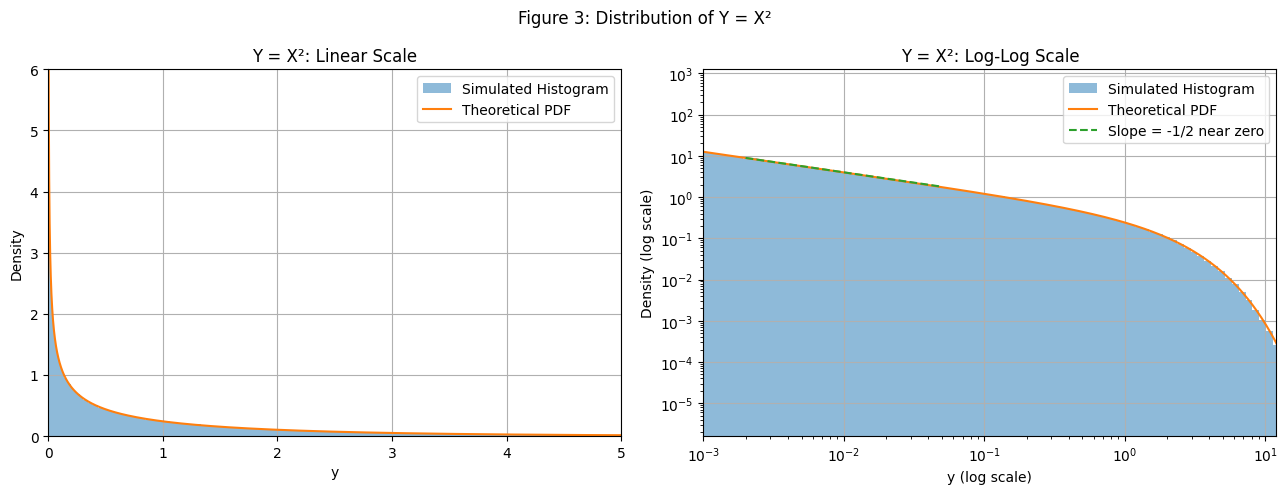

In [9]:
# Step 3: Figure 3

# Log-spaced bins to show the behavior near zero
bins3 = np.geomspace(1e-6, 20, 150)
x_plot3 = np.geomspace(1e-5, 20, 1000)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel 1: Linear axes
axes[0].hist(y3, bins=bins3, density=True,
             alpha=0.5, label="Simulated Histogram")

axes[0].plot(x_plot3, y_pdf(x_plot3),
             label="Theoretical PDF")

axes[0].set_title("Y = X²: Linear Scale")
axes[0].set_xlabel("y")
axes[0].set_ylabel("Density")
axes[0].set_xlim(0, 5)
axes[0].set_ylim(0, 6)
axes[0].legend()
axes[0].grid(True)

# Panel 2: Log-log axes
axes[1].hist(y3, bins=bins3, density=True,
             alpha=0.5, label="Simulated Histogram")

axes[1].plot(x_plot3, y_pdf(x_plot3),
             label="Theoretical PDF")

# Reference line showing slope -1/2 near zero
x_ref = np.geomspace(0.002, 0.05, 100)
y_ref = (1 / np.sqrt(2 * np.pi)) * x_ref**(-0.5)

axes[1].plot(x_ref, y_ref, "--",
             label="Slope = -1/2 near zero")

axes[1].set_xscale("log")
axes[1].set_yscale("log")

axes[1].set_title("Y = X²: Log-Log Scale")
axes[1].set_xlabel("y (log scale)")
axes[1].set_ylabel("Density (log scale)")
axes[1].set_xlim(1e-3, 12)
axes[1].legend()
axes[1].grid(True)

plt.suptitle("Figure 3: Distribution of Y = X²")
plt.tight_layout()
plt.show()

### Figure 3 Interpretation

Figure 3 compares the simulated distribution of
$Y=X^2$ with its theoretical PDF using one million
samples. Logarithmically spaced bins are used to
better capture the behavior near zero.

On the linear scale, the density rises sharply near
zero and decreases as $y$ increases. The log-log
plot makes the divergence more visible.

Near zero,

$$
f_Y(y)\approx\frac{1}{\sqrt{2\pi}}y^{-1/2}.
$$

Taking logarithms gives

$$
\ln f_Y(y)\approx
-\frac{1}{2}\ln y-\frac{1}{2}\ln(2\pi).
$$

Therefore, the log-log slope approaches $-1/2$.

The numerical integration confirms that the PDF
integrates to approximately one despite diverging
near zero.

The empirical probabilities, median, mean, and
variance are close to their analytical values.

The median is substantially smaller than the mean,
reflecting the concentration of probability near
zero and the long right tail of the distribution.

## Bonus B: A Distribution With No Mean

Let $X$ and $Y$ be independent standard Gaussian random
variables, and define

$$
Z=\frac{X}{Y}.
$$

### Derivation of the Cauchy PDF

Because $X$ and $Y$ are independent standard Gaussian
random variables, their joint PDF is

$$
f_{X,Y}(x,y)=\frac{1}{2\pi}
e^{-(x^2+y^2)/2}.
$$

Use the transformation

$$
Z=\frac{X}{Y},\qquad W=Y.
$$

The inverse transformation is

$$
X=ZW,\qquad Y=W.
$$

The absolute value of the Jacobian determinant is

$$
|J|=|w|.
$$

Therefore, the PDF of $Z$ is

$$
f_Z(z)=\int_{-\infty}^{\infty}
f_{X,Y}(zw,w)|w|\,dw.
$$

Substituting the joint Gaussian density,

$$
f_Z(z)=\frac{1}{2\pi}
\int_{-\infty}^{\infty}
|w|e^{-(1+z^2)w^2/2}\,dw.
$$

By symmetry,

$$
f_Z(z)=\frac{1}{\pi}
\int_0^\infty
w e^{-(1+z^2)w^2/2}\,dw.
$$

Evaluating the integral,

$$
f_Z(z)=\frac{1}{\pi(1+z^2)},
\qquad -\infty<z<\infty.
$$

This is the standard Cauchy distribution.

### Why the Mean Does Not Exist

The Cauchy distribution has heavy tails, and its
expected absolute value diverges:

$$
E[|Z|]=
\int_{-\infty}^{\infty}
\frac{|z|}{\pi(1+z^2)}\,dz
=\infty.
$$

Therefore, the ordinary population mean is undefined.
The symmetry of the distribution does not make the
mean equal to zero.

For independent standard Cauchy random variables,

$$
\frac{Z_1+\cdots+Z_N}{N}
\sim\operatorname{Cauchy}(0,1).
$$

Thus, the sample mean has the same distribution
regardless of the sample size. It does not become
more concentrated around zero as N increases.

The population median, however, is zero, and the
sample median provides a more reliable estimator
of the center.

In [10]:
# Bonus B: Cauchy Distribution

N_bonus = 1000000

# Generate two independent Gaussian arrays
x_bonus = bonus_b_rng.standard_normal(N_bonus)
y_bonus = bonus_b_rng.standard_normal(N_bonus)

# Generate Cauchy samples
z_bonus = x_bonus / y_bonus

sample_sizes = [1000, 10000, 100000, 1000000]

means_bonus = []
medians_bonus = []

print("Bonus B: Cauchy Distribution")
print(f"{'Sample Size':<15} {'Sample Mean':>15} {'Sample Median':>15}")
print("-" * 47)

for n in sample_sizes:
    sample_mean = np.mean(z_bonus[:n])
    sample_median = np.median(z_bonus[:n])

    means_bonus.append(sample_mean)
    medians_bonus.append(sample_median)

    print(f"{n:<15} {sample_mean:>15.6f} {sample_median:>15.6f}")

Bonus B: Cauchy Distribution
Sample Size         Sample Mean   Sample Median
-----------------------------------------------
1000                   1.375052       -0.015679
10000                 -0.645323        0.000578
100000                 0.911730       -0.006251
1000000               -7.465945       -0.000496


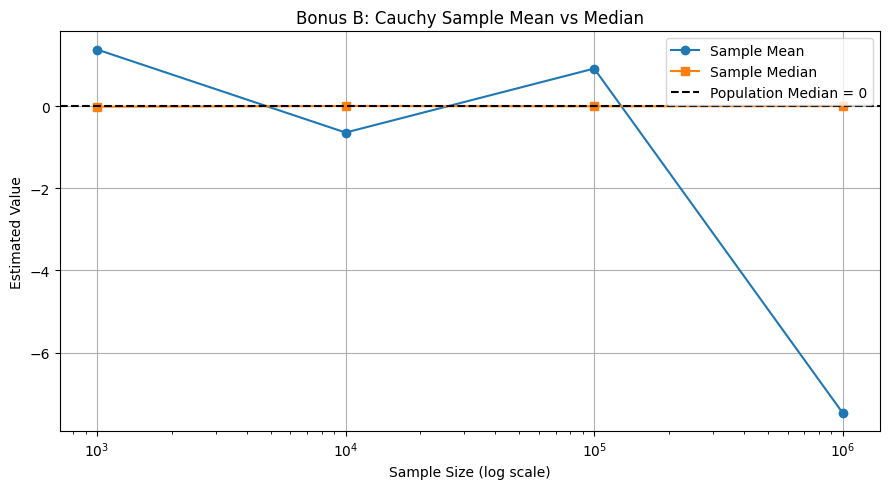

In [11]:
# Bonus B: Mean and Median Comparison

plt.figure(figsize=(9, 5))

plt.plot(sample_sizes, means_bonus, "o-",
         label="Sample Mean")

plt.plot(sample_sizes, medians_bonus, "s-",
         label="Sample Median")

plt.axhline(0, color="black", linestyle="--",
            label="Population Median = 0")

plt.xscale("log")

plt.xlabel("Sample Size (log scale)")
plt.ylabel("Estimated Value")
plt.title("Bonus B: Cauchy Sample Mean vs Median")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Bonus B Interpretation

The simulation demonstrates that the Cauchy sample
mean does not reliably converge as the sample size
increases.

Even with one million samples, the mean can differ
substantially from zero because occasional extreme
observations have a large influence on the average.

The sample median remains close to zero because it
is much less sensitive to extreme values.

The sample mean of one million independent standard
Cauchy variables has the same standard Cauchy
distribution as a single observation. Therefore,
increasing the sample size does not make the sample
mean more reliable.

If measurement noise follows a Cauchy distribution,
the sample median is preferable to the sample mean
for estimating its location.